# Système de recommandation hybride : réduire le biais de popularité (Goodreads)

**Équipe :** Amine et Ella · **Owner :** les deux (Amine assemble les sections 1, 3, 4, 5 ; Ella les sections 2 et 6).

**Ce que fait ce notebook :** il suit les étapes de l'énoncé (1 à 6) et affiche les tableaux, figures et
exemples utilisés dans le rapport. La logique est dans `src/` (code commenté) ; le notebook l'appelle.

**Entrée :** les fichiers produits par le pipeline (à lancer avant, dans cet ordre) :

```
python scripts/run_pipeline.py --force     # données, modèles, évaluation
python scripts/tune_k.py                   # choix de k sur la validation
python scripts/run_pipeline.py             # réévaluation du test avec ce k
```

**Sortie :** les chiffres et figures du rapport (aucun réentraînement ici).

In [4]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.utils.config import load_config
from src.labels import METRIC_LABEL, MODEL_LABEL, fr_metric, model_label, popularity_thresholds

cfg = load_config()
P, T, F = cfg["paths"]["processed_dir"], cfg["paths"]["tables_dir"], cfg["paths"]["figures_dir"]
pd.set_option("display.max_columns", 30)

def show(path, width=850):
    if Path(path).exists():
        display(Image(filename=str(path), width=width))
    else:
        print("Figure absente :", path, "-> lancer le pipeline.")

## 1. Domaine et jeu de données

Domaine : **livres** (bandes dessinées et romans graphiques). Jeu de données public **UCSD Book Graph**
(Goodreads, Wan & McAuley, 2017), sous-ensemble *Comics & Graphic* : 89 411 livres et 7 347 630
interactions. Il contient les **interactions utilisateur-livre** (lu, note, date) et des **descriptions**
des livres (texte + étagères populaires des lecteurs), comme demandé.

Pour tenir sur un ordinateur portable, nous échantillonnons des lecteurs (`data.n_users_sample`).

In [5]:
print("Sous-ensemble :", cfg["data"]["interactions_file"], "|", cfg["data"]["books_file"])
print("Lecteurs échantillonnés :", cfg["data"]["n_users_sample"],
      "| interaction positive : lu ou note >=", cfg["data"]["positive_rating"])

Sous-ensemble : goodreads_interactions_comics_graphic.json.gz | goodreads_books_comics_graphic.json.gz
Lecteurs échantillonnés : 50000 | interaction positive : lu ou note >= 4


## 2. Analyse et préparation des données

Statistiques à chaque étape (brut, nettoyé, entraînement) : nombre de lecteurs, de livres,
d'interactions, **taux de remplissage** (densité) et **sparsité** de la matrice, concentration de la
popularité (indice de Gini). Nettoyage : interactions positives uniquement, filtre *k-core* (au moins
5 interactions par lecteur et par livre), textes nettoyés. Découpage **temporel par lecteur** :
les 20 % d'interactions les plus récentes en test, les 10 % précédentes en validation.

In [6]:
stats = pd.read_csv(T / "dataset_stats.csv")
stats

,stage,n_users,n_items,n_interactions,density,sparsity,user_interactions_mean,user_interactions_median,user_interactions_min,user_interactions_max,item_interactions_mean,item_interactions_median,item_interactions_min,item_interactions_max,gini,top_20pct_share,low_popularity_share
0,raw,50000,66018,1060421,0.000321,0.999679,21.208420,3.0,1,3610,16.062604,3.0,1,6467,0.777964,0.818971,0.504787
1,clean,14791,20449,575742,0.001904,0.998096,38.925157,15.0,5,2195,28.155020,11.0,5,3415,0.627357,0.685368,0.000000
2,train,14791,19996,338030,0.001143,0.998857,22.853762,9.0,1,1186,16.904881,6.0,1,2887,0.678003,0.725714,0.286957


Livres : 20061 | médiane des lecteurs par livre : 6 | max : 2887
Best-seller : >= 57 lecteurs (top 5 %) | intermédiaire : >= 17 (top 20 %) | pépite : le reste (80 %)
Les 20 % de livres les plus lus concentrent 73% des interactions d'entraînement.


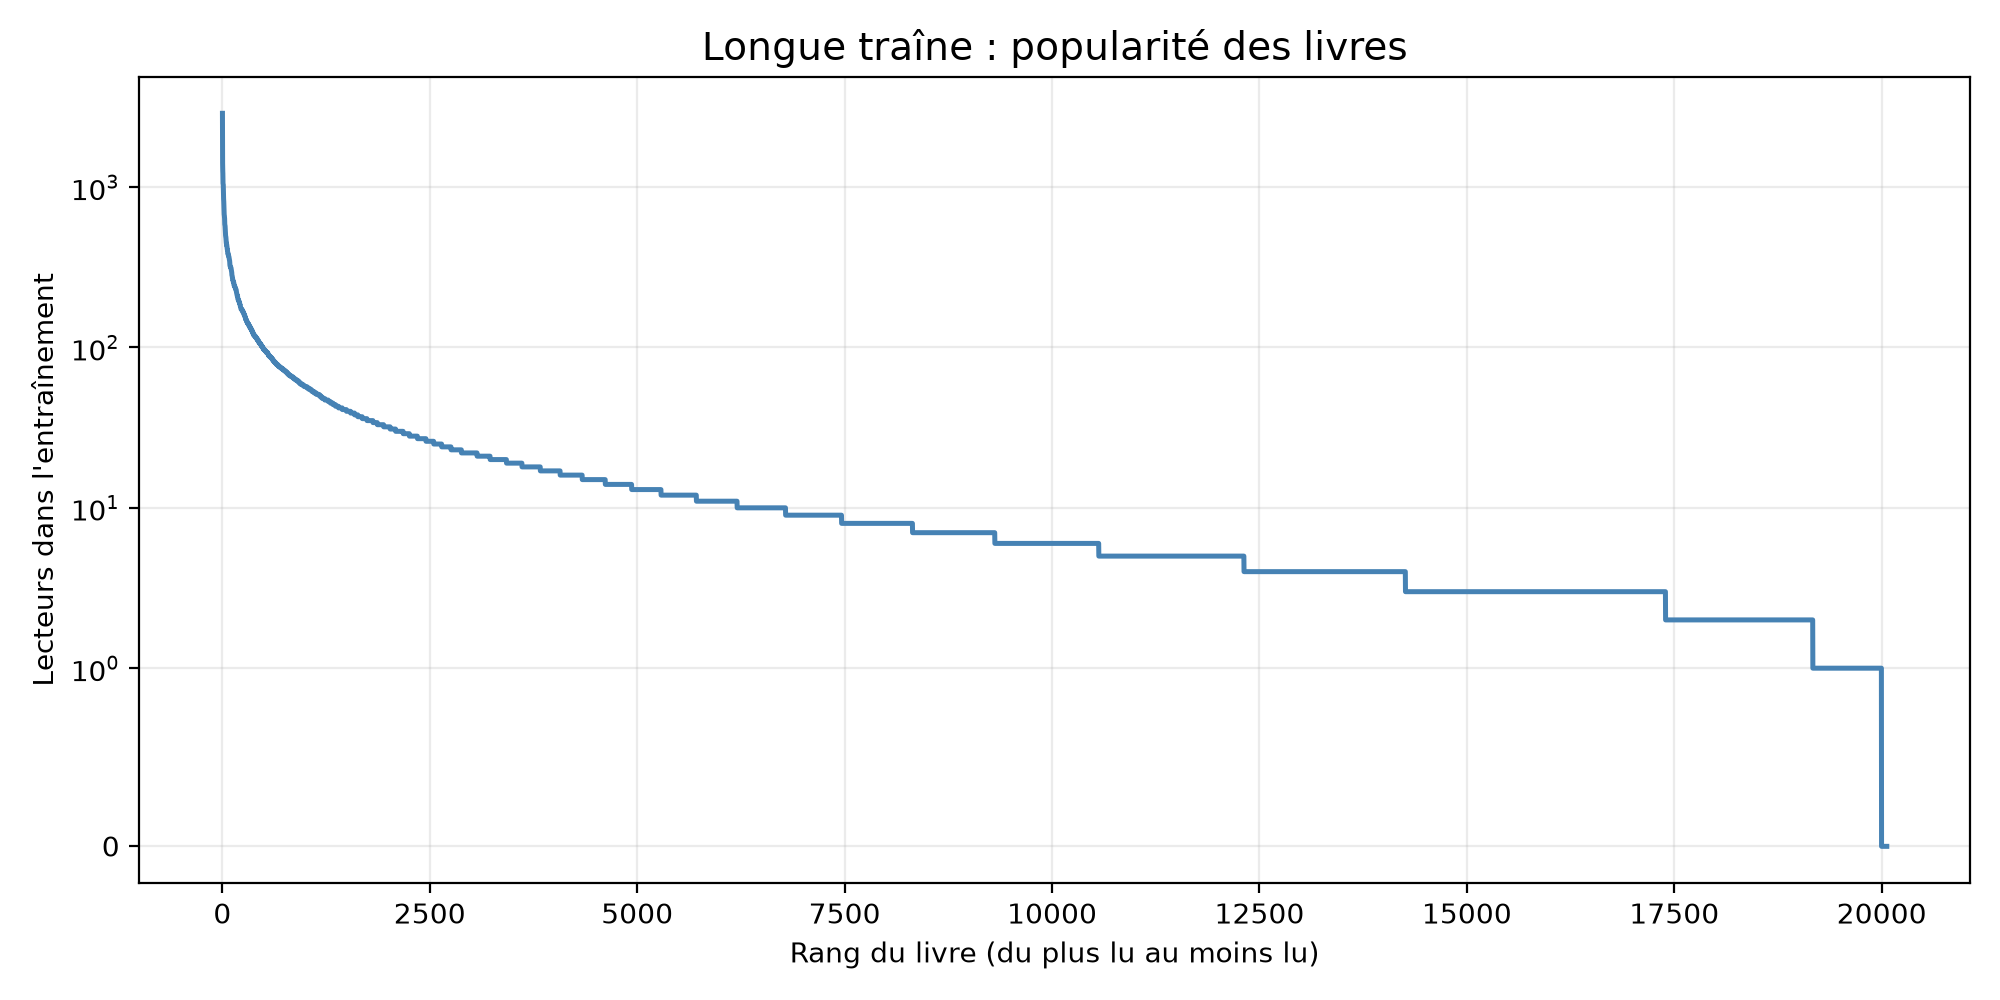

In [7]:
n_items = np.load(P / "n_items.npy")
mid_min, head_min = popularity_thresholds(n_items)
print(f"Livres : {len(n_items)} | médiane des lecteurs par livre : {np.median(n_items):.0f} | max : {n_items.max():.0f}")
print(f"Best-seller : >= {head_min:.0f} lecteurs (top 5 %) | intermédiaire : >= {mid_min:.0f} (top 20 %) | pépite : le reste (80 %)")
top20 = np.sort(n_items)[::-1][: int(0.2 * len(n_items))].sum() / n_items.sum()
print(f"Les 20 % de livres les plus lus concentrent {top20:.0%} des interactions d'entraînement.")
show(F / "long_tail.png")

In [8]:
cold_books = json.load(open(P / "cold_books.json", encoding="utf-8"))["book_ids"]
cold_users = json.load(open(P / "cold_users.json", encoding="utf-8"))["user_ids"]
print(f"Démarrage à froid simulé : {len(cold_books)} livres et {len(cold_users)} lecteurs rendus « nouveaux »")
print("(les données datent de 2017 : on cache la plupart des interactions d'entraînement de ces livres / lecteurs)")

Démarrage à froid simulé : 2006 livres et 1479 lecteurs rendus « nouveaux »
(les données datent de 2017 : on cache la plupart des interactions d'entraînement de ces livres / lecteurs)


## 3. Approches de base

- **Popularité** (baseline) : recommande les livres les plus lus.
- **ALS** (filtrage collaboratif, feedback implicite) : un vecteur par lecteur et par livre, appris sur
  la matrice lecteurs × livres avec une confiance `1 + α·r` (`src/models/als_model.py`).
- **TF-IDF** (basé sur le contenu) : un vecteur par livre à partir de sa description et de ses
  étagères (sans les étagères de rangement comme « to-read ») ; le profil d'un lecteur est la moyenne des
  livres qu'il a aimés (`src/models/content_tfidf.py`).
- *Approche récente (perspective) : embeddings de phrases MiniLM — non implémentée.*

In [9]:
from src import recommend
art = recommend.load_artifacts(cfg)
print("Matrice d'entraînement :", art["train"].shape, "| interactions :", art["train"].nnz)
print("Facteurs ALS :", art["als"].item_factors.shape, "| vecteurs TF-IDF :", art["item_vectors"].shape)

Matrice d'entraînement : (14791, 20061) | interactions : 338030
Facteurs ALS : (20061, 64) | vecteurs TF-IDF : (20061, 50000)


## 4. Approche hybride : pondérée, avec un poids adaptatif par livre

`score(u, i) = α_i · ALS(u, i) + (1 − α_i) · contenu(u, i)` avec `α_i = n_i / (n_i + k)`,
où `n_i` est le nombre de lecteurs du livre dans l'entraînement (scores normalisés min-max par lecteur).

**Justification :** le vecteur ALS d'un livre n'est fiable que si le livre a assez de lecteurs.
Un livre peu lu est donc classé surtout sur son contenu, un livre très lu surtout par ALS.
`k` = nombre de lecteurs pour lequel les deux branches pèsent autant.

**Choix de k (validation) :** le plus grand k dont le NDCG@20 reste à moins de 5 % du meilleur
(`gate.ndcg_tolerance`) — un compromis explicite entre pertinence et découverte.

In [10]:
sweep = pd.read_csv(T / "k_sweep_val.csv")
best = json.load(open(T / "best_k.json", encoding="utf-8"))
print("k retenu :", best["k"], "|", best.get("selection_rule", ""))
sweep.round(4)

k retenu : 50.0 | largest k with NDCG@20 >= 0.95 x best NDCG@20


,k,recall,ndcg,cold_recall,coverage,novelty,tail_share,variety
0,0.0,0.2838,0.1595,0.0003,0.2609,6.2890,0.0302,0.0588
1,1.0,0.2958,0.1699,0.0017,0.2930,6.3006,0.0480,0.0581
2,2.0,0.2976,0.1723,0.0032,0.3175,6.3839,0.0583,0.0581
3,5.0,0.3005,0.1756,0.0093,0.3776,6.5935,0.0819,0.0581
4,10.0,0.3049,0.1779,0.0207,0.4551,6.8661,0.1155,0.0583
5,20.0,0.3039,0.1780,0.0483,0.5558,7.3108,0.1786,0.0589
6,50.0,0.2862,0.1697,0.0827,0.6702,8.2214,0.3239,0.0602
7,100.0,0.2666,0.1575,0.1013,0.7118,8.9633,0.4477,0.0621
8,200.0,0.2475,0.1399,0.1120,0.7250,9.5414,0.5452,0.0636
9,500.0,0.2192,0.1165,0.1168,0.7272,10.0134,0.6268,0.0647


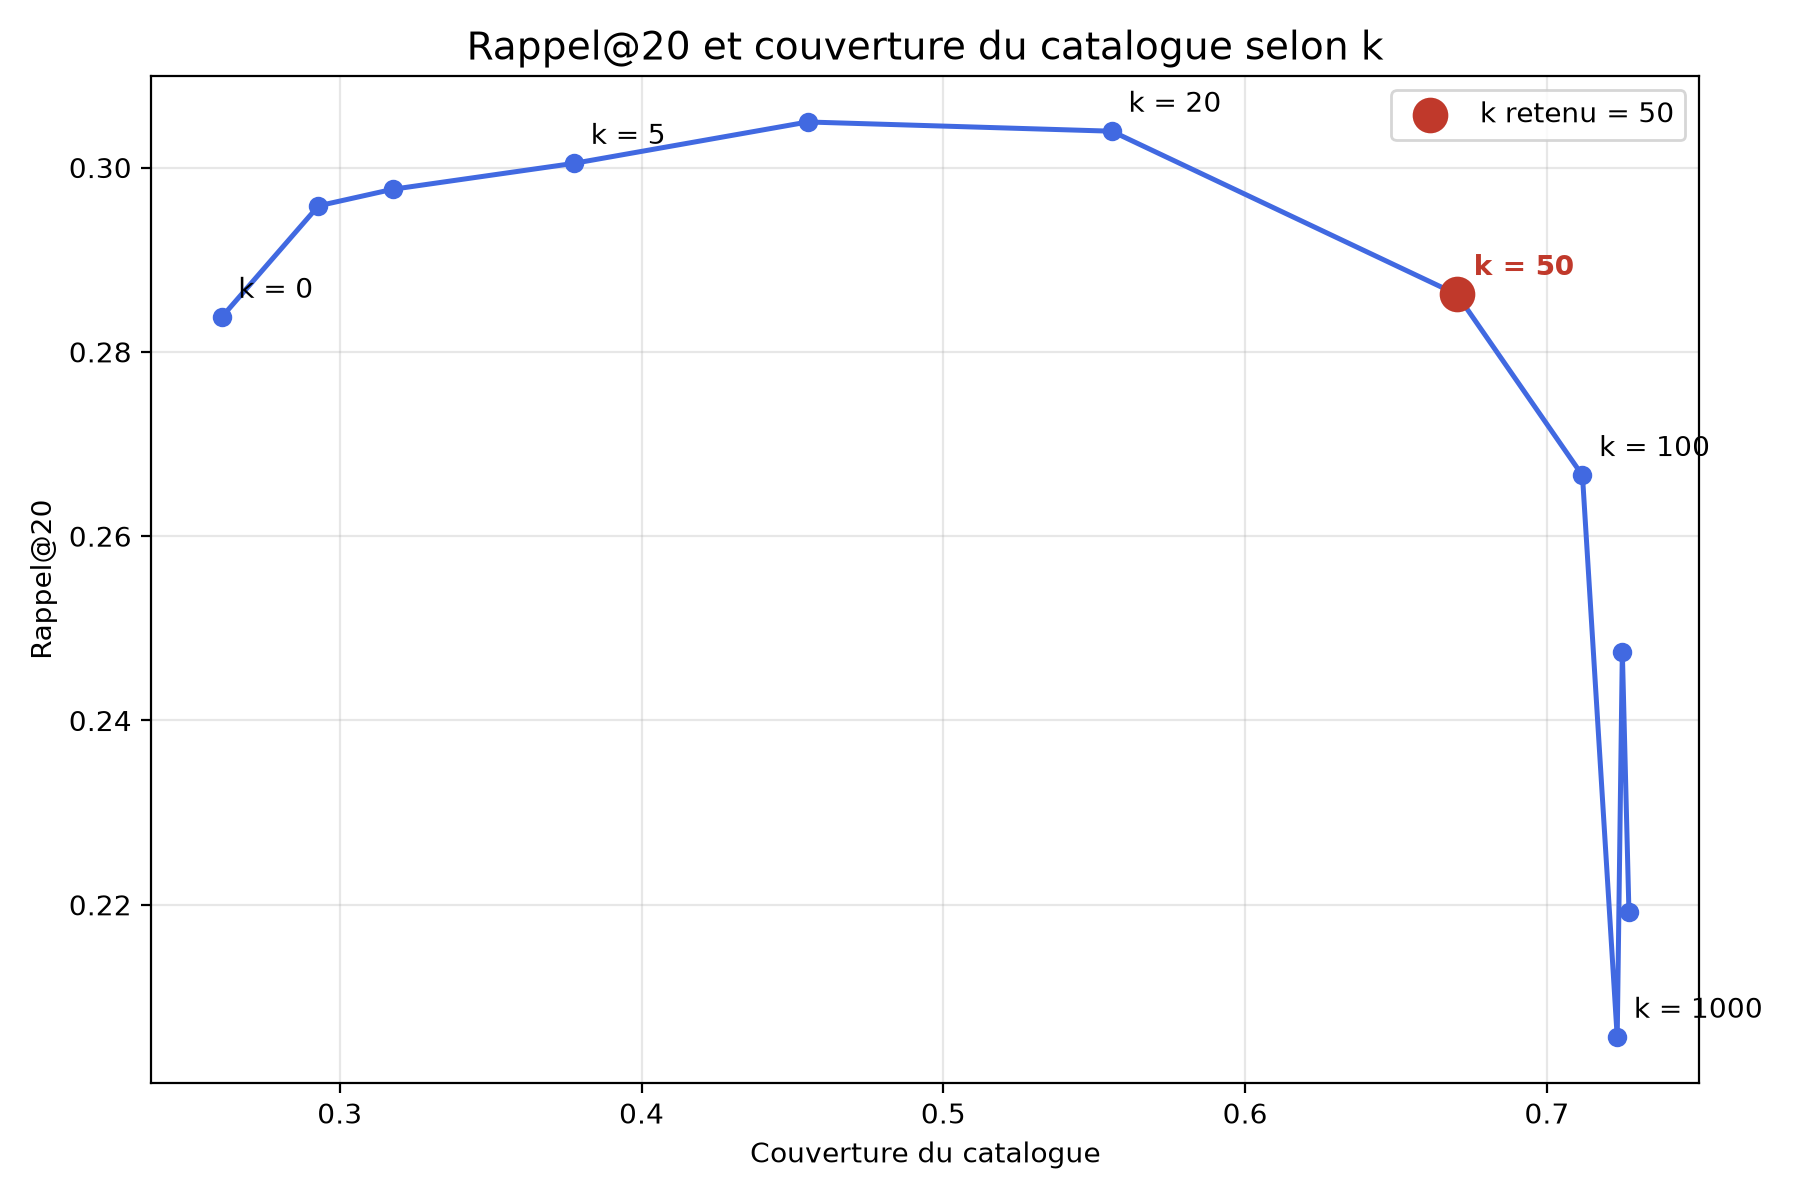

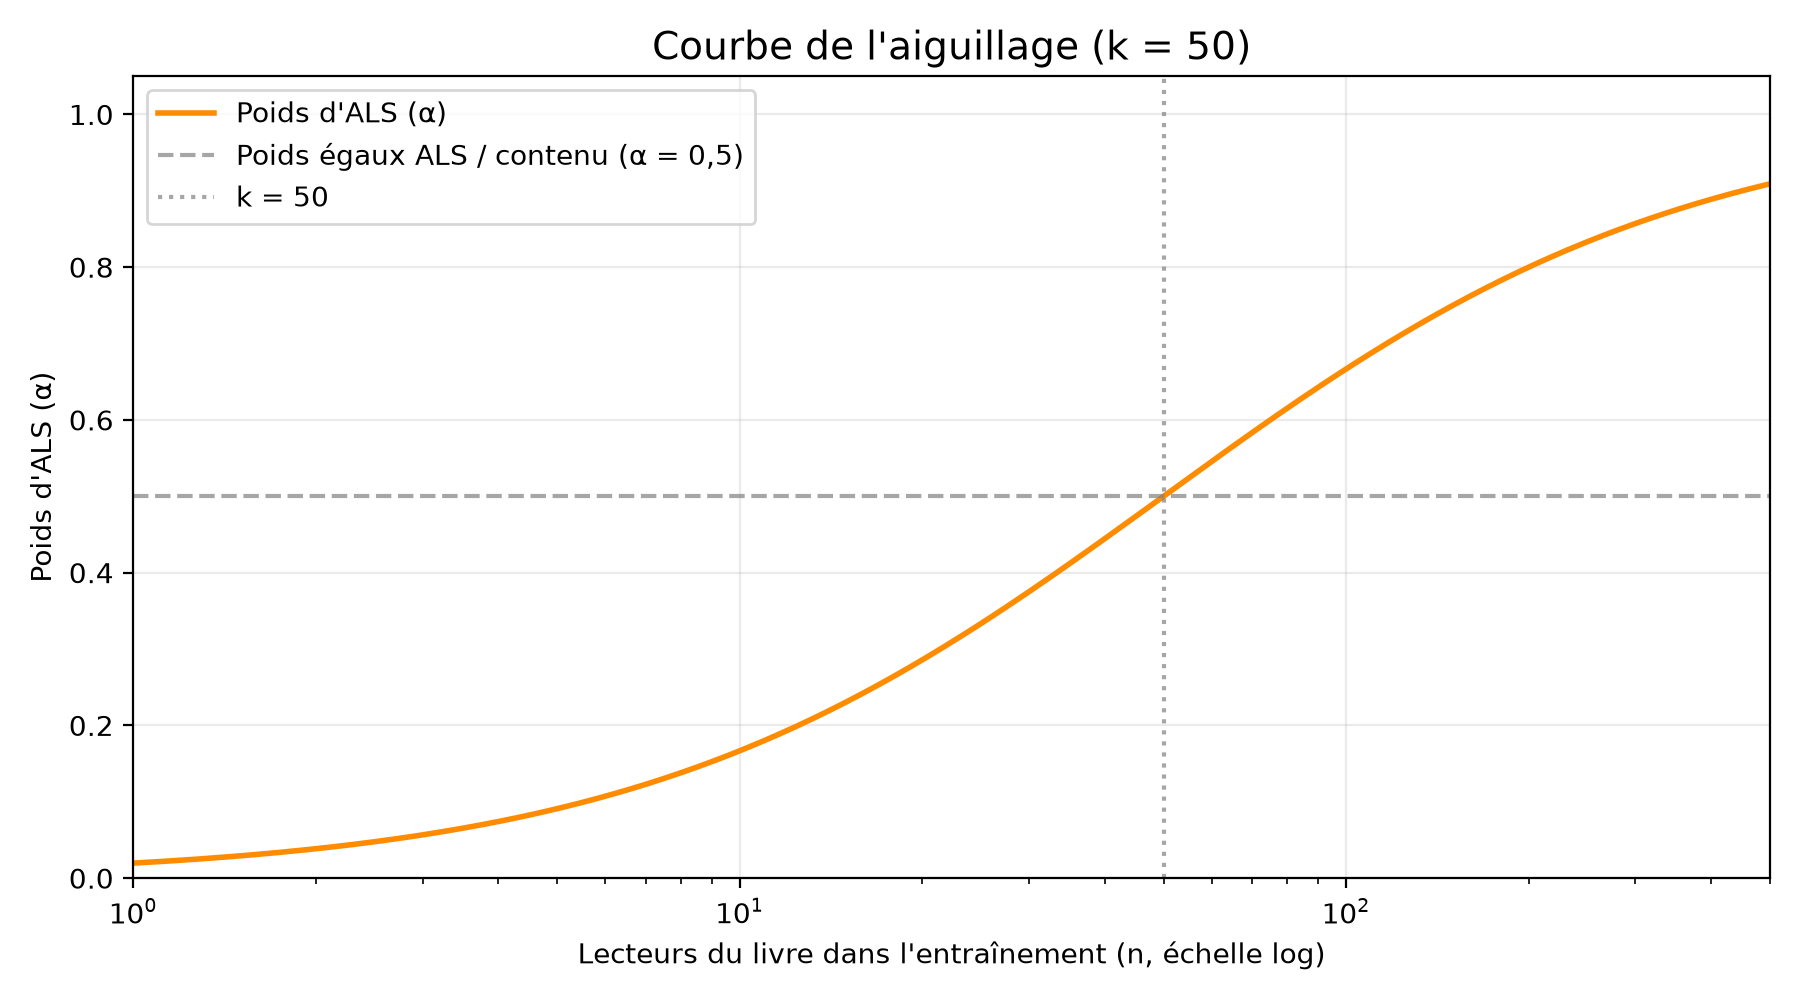

In [11]:
show(F / "tradeoff_curve.png")
show(F / "gate_curve.png", width=650)

## 5. Évaluation expérimentale (jeu de test)

L'hybride est comparé à **chaque approche seule** et à la **baseline de popularité**, avec des métriques de
précision (Précision, Rappel, NDCG, HR @K) et **au-delà de la précision** (couverture, nouveauté, part de
pépites). Le **démarrage à froid** est testé à part : livres nouveaux et lecteurs nouveaux.

In [12]:
test = pd.read_csv(T / "test_metrics.csv", index_col=0)
cols = ["all/precision@20", "all/recall@20", "all/ndcg@20", "all/hr@20",
        "cold_items/recall@20", "cold_users/recall@20", "coverage", "novelty", "tail_share"]
cols = [c for c in cols if c in test.columns]
table = test[cols].copy()
table.index = [model_label(m) for m in table.index]
table.columns = [METRIC_LABEL.get(c, c) for c in cols]
table.round(4)

,Précision@20,Rappel@20,NDCG@20,Taux de succès@20,Rappel@20 · livres nouveaux,Rappel@20 · lecteurs nouveaux,Couverture du catalogue,Nouveauté,Part de pépites
Popularité,0.0110,0.0622,0.0367,0.1625,0.0000,0.0672,0.0029,3.8702,0.0000
ALS (collaboratif),0.0317,0.2027,0.1206,0.3878,0.0000,0.1404,0.2602,6.1905,0.0167
TF‑IDF (contenu),0.0156,0.1133,0.0572,0.2053,0.0706,0.0643,0.6983,10.3206,0.6866
Hybride 50/50,0.0287,0.1795,0.1107,0.3419,0.0093,0.1148,0.5185,7.8846,0.1674
Hybride adaptatif (k = 50),0.0303,0.2009,0.1212,0.3711,0.0545,0.1277,0.6700,8.2209,0.3237


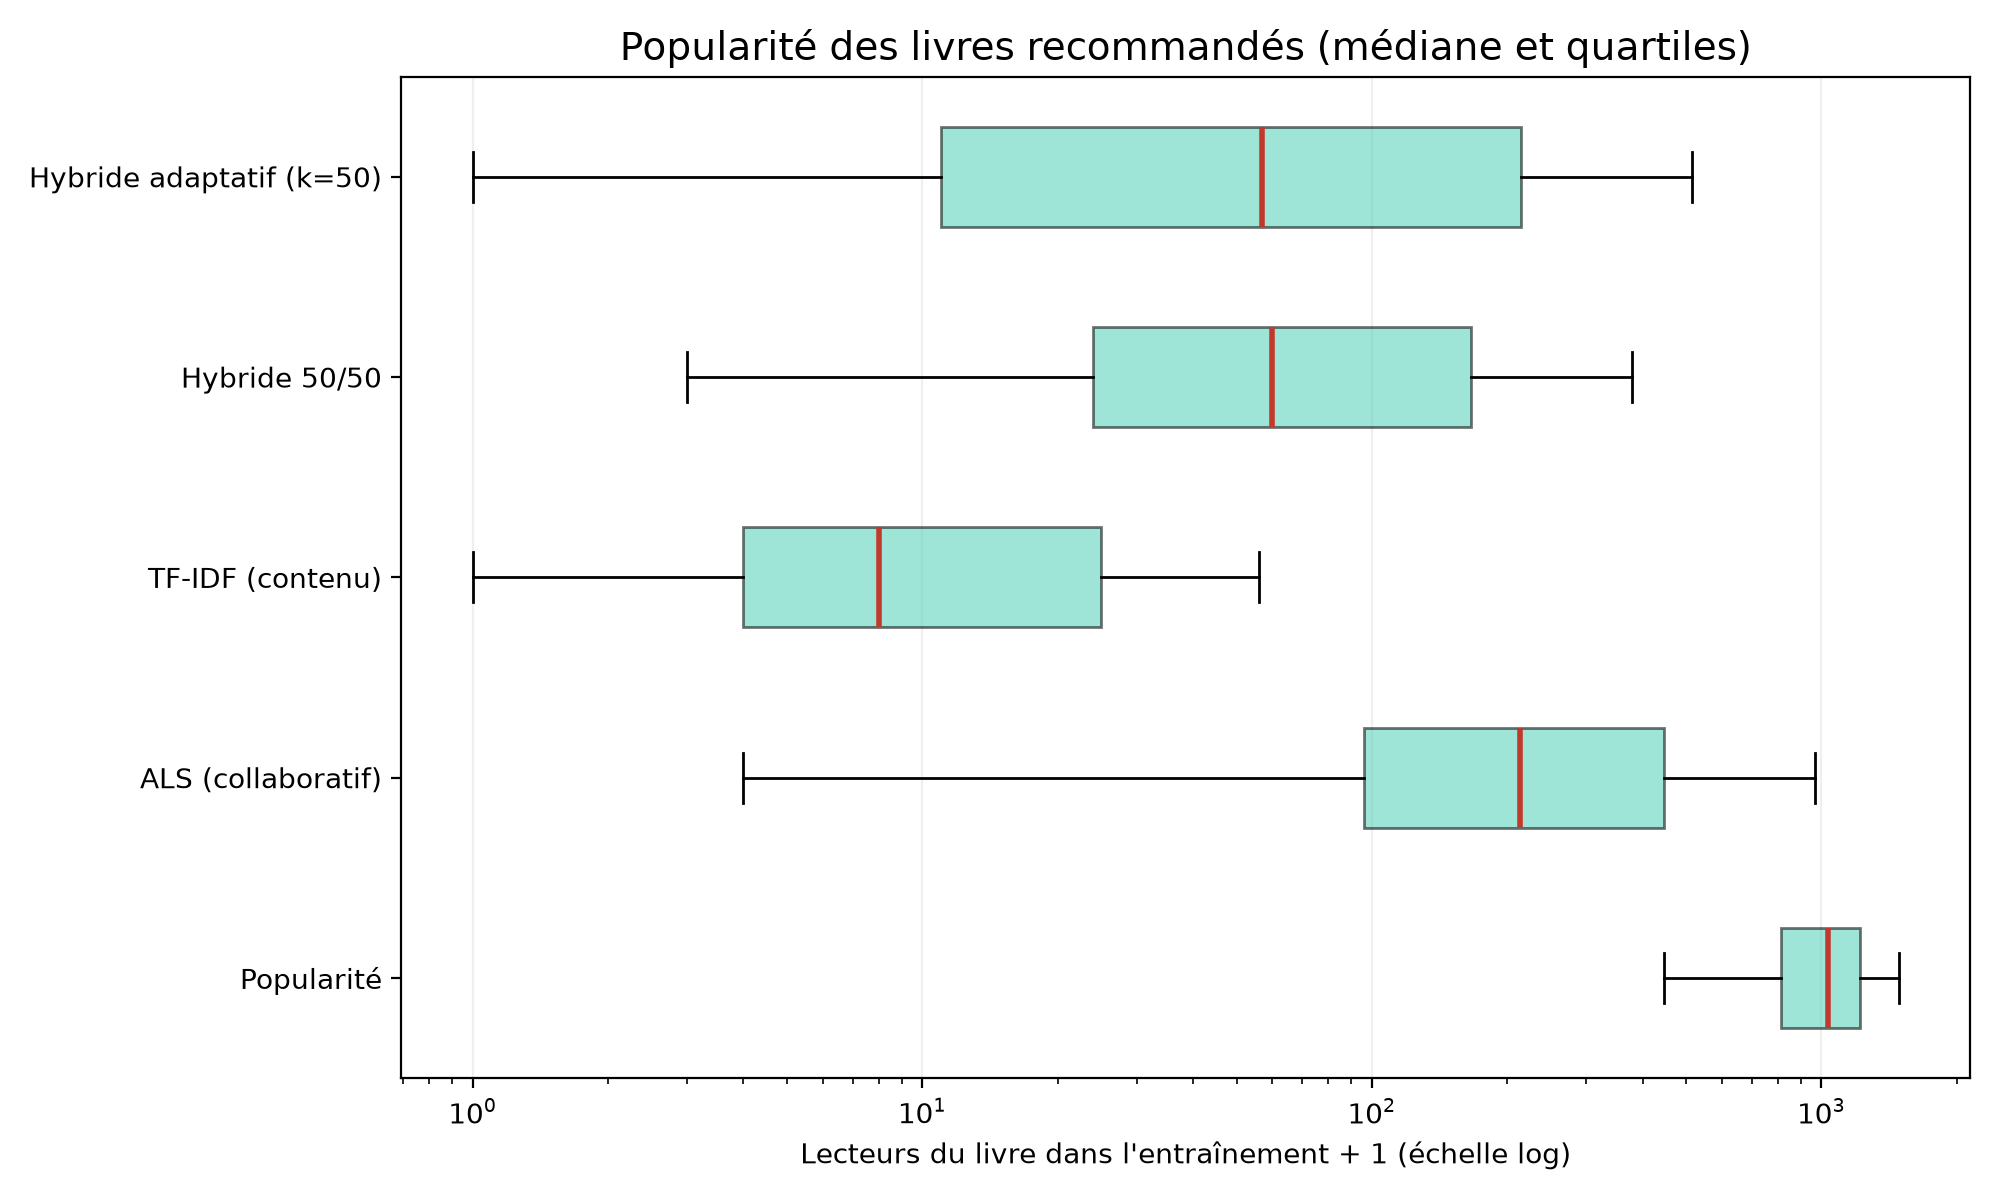

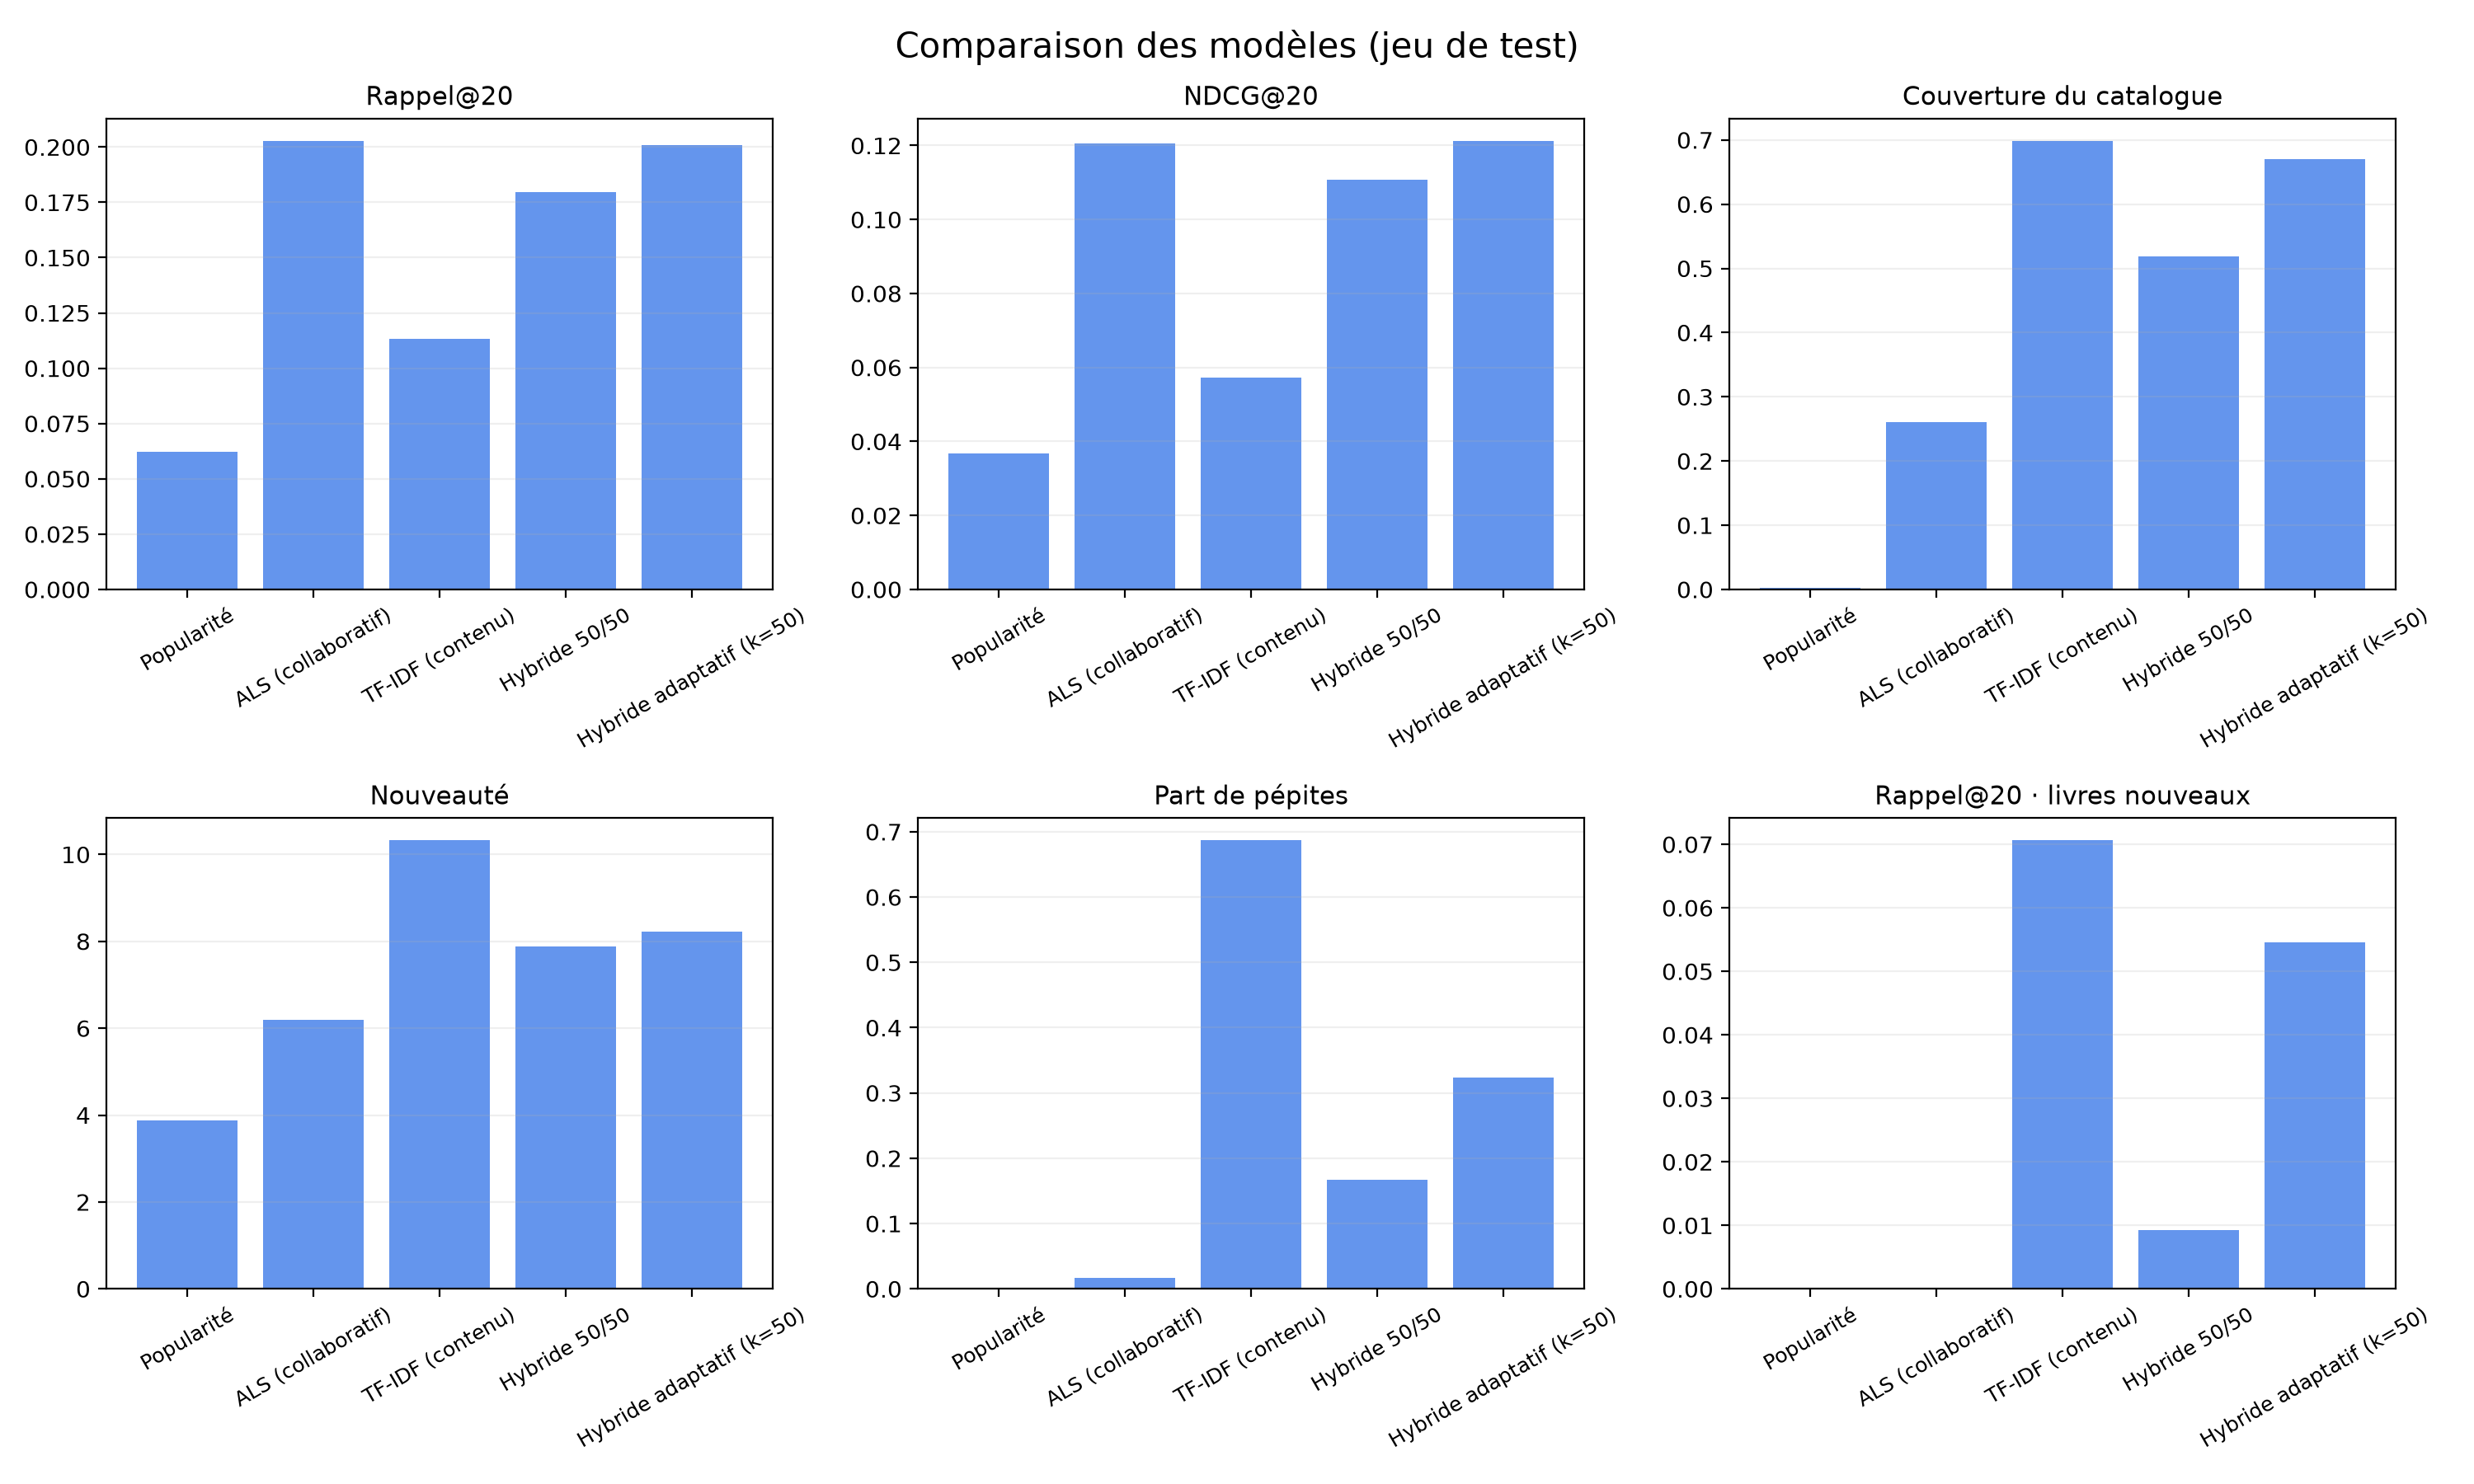

In [13]:
show(F / "popularity_of_recs.png")
show(F / "baseline_bars.png")

**Lecture des résultats (à compléter avec les chiffres finaux) :** quel modèle est le plus pertinent,
lequel ouvre le plus la longue traîne, et où l'hybride adaptatif se place. Être honnête : l'hybride
adaptatif fait confiance à ALS pour les livres très lus, et ALS favorise les livres populaires ; son
intérêt principal est sur les **livres nouveaux**, alors que l'hybride 50/50 peut donner plus de diversité
globale.

## 6. Démonstration : recommandations expliquées

Trois lecteurs de démonstration, ALS contre hybride adaptatif, avec l'explication de chaque livre.
L'interface complète : `streamlit run app/streamlit_app.py`.

In [14]:
pd.set_option("display.max_colwidth", 160)
for user in art["demo_users"][:3]:
    print("=" * 100)
    print("Lecteur", user, "-", art["train"][art["user2idx"][user]].nnz, "livres lus")
    for model in ("als", "gate"):
        recs = recommend.recommend_for_user(user, art, model_name=model, top_n=5)
        print(f"\n  {MODEL_LABEL[model]} :")
        display(recs[["rank", "title", "n", "popularity", "explanation"]])

Lecteur 7e25448742ab91bc13f2f74b1a5ca426 - 49 livres lus

  ALS (collaboratif) :


,rank,title,n,popularity,explanation
0,1,"Maus I: A Survivor's Tale: My Father Bleeds History (Maus, #1)",1276,head,"Parce que vous avez aimé « Bleach, Volume 05 ». Apprécié par des lecteurs aux goûts proches des vôtres."
1,2,"Attack on Titan: No Regrets, Volume 01",52,mid,"Parce que vous avez aimé « Attack on Titan, Volume 12 ». Tags communs : science-fiction, attack-on-titan, horror. Apprécié par des lecteurs aux goûts proche..."
2,3,"Maus II: A Survivor's Tale: And Here My Troubles Began (Maus, #2)",706,head,"Parce que vous avez aimé « 進撃の巨人 18 [Shingeki no Kyojin 18] (Attack on Titan, #18) ». Apprécié par des lecteurs aux goûts proches des vôtres."
3,4,"Fullmetal Alchemist, Vol. 2 (Fullmetal Alchemist, #2)",182,head,"Parce que vous avez aimé « One Piece, Volume 02: Buggy the Clown (One Piece, #2) ». Tags communs : action, science-fiction, shounen. Apprécié par des lecteu..."
4,5,"Fullmetal Alchemist, Vol. 3 (Fullmetal Alchemist, #3)",160,head,"Parce que vous avez aimé « Bleach, Volume 11 ». Tags communs : action, science-fiction, adventure. Apprécié par des lecteurs aux goûts proches des vôtres."



  Hybride adaptatif :


,rank,title,n,popularity,explanation
0,1,"Bleach, Volume 22",67,head,"Parce que vous avez aimé « Bleach, Volume 16 ». Tags communs : action, shounen, manga-read. Choisi à la fois par les lecteurs proches et par le contenu."
1,2,"Maus II: A Survivor's Tale: And Here My Troubles Began (Maus, #2)",706,head,"Parce que vous avez aimé « 進撃の巨人 18 [Shingeki no Kyojin 18] (Attack on Titan, #18) ». Choisi surtout grâce aux lecteurs aux goûts proches."
2,3,"Bleach, Volume 20",70,head,"Parce que vous avez aimé « Bleach, Volume 16 ». Tags communs : action, shounen, manga-read. Choisi à la fois par les lecteurs proches et par le contenu."
3,4,"Bleach, Volume 18",76,head,"Parce que vous avez aimé « Bleach, Volume 16 ». Tags communs : action, shounen, manga-read. Choisi surtout grâce aux lecteurs aux goûts proches."
4,5,"One Piece, Volume 01: Romance Dawn (One Piece, #1)",371,head,"Parce que vous avez aimé « One Piece, Volume 02: Buggy the Clown (One Piece, #2) ». Tags communs : shounen, adventure, manga-comics. Choisi surtout grâce au..."


Lecteur c21798b424a6bc114918fd0bcd057b70 - 392 livres lus

  ALS (collaboratif) :


,rank,title,n,popularity,explanation
0,1,"Persepolis, Volume 1",210,head,"Parce que vous avez aimé « Batwoman, Vol. 1: Hydrology ». Tags communs : history. Apprécié par des lecteurs aux goûts proches des vôtres."
1,2,Green Arrow: Year One,56,mid,"Parce que vous avez aimé « Justice League: Trinity War ». Tags communs : superheroes, superhero, dc. Apprécié par des lecteurs aux goûts proches des vôtres."
2,3,V for Vendetta,1484,head,"Parce que vous avez aimé « Watchmen ». Tags communs : science-fiction, graphic, sci-fi. Apprécié par des lecteurs aux goûts proches des vôtres."
3,4,Black Hole,314,head,"Parce que vous avez aimé « All-Star Western, Volume 1: Guns and Gotham ». Tags communs : science-fiction, graphic, sci-fi. Apprécié par des lecteurs aux goû..."
4,5,"Transmetropolitan, Vol. 1: Back on the Street (Transmetropolitan, #1)",314,head,"Parce que vous avez aimé « Hellblazer: Original Sins ». Tags communs : science-fiction, graphic, sci-fi. Apprécié par des lecteurs aux goûts proches des vôt..."


... (2 outputs left out)

Lecteur fd41e74cc9d51df93ae6db93630bf02b - 36 livres lus

  ALS (collaboratif) :


,rank,title,n,popularity,explanation
0,1,Marvel 1602,498,head,"Parce que vous avez aimé « Yu-Gi-Oh!: Millennium World, Vol. 3: The Return of Bakura (Yu-Gi-Oh! Millennium World, #3) ». Tags communs : graphic. Apprécié pa..."
1,2,Preludes & Nocturnes (The Sandman #1),1411,head,"Parce que vous avez aimé « Yu-Gi-Oh! Vol. 4: Kaiba's Revenge (Yu-Gi-Oh!, #4) ». Tags communs : graphic, mythology. Apprécié par des lecteurs aux goûts proch..."
2,3,V for Vendetta,1484,head,"Parce que vous avez aimé « Yu-Gi-Oh!: Millennium World, Vol. 3: The Return of Bakura (Yu-Gi-Oh! Millennium World, #3) ». Tags communs : graphic. Apprécié pa..."
3,4,Watchmen,2887,head,"Parce que vous avez aimé « Yu-Gi-Oh!: Millennium World, Vol. 3: The Return of Bakura (Yu-Gi-Oh! Millennium World, #3) ». Tags communs : graphic. Apprécié pa..."
4,5,"Ms. Marvel, Vol. 2: Generation Why",386,head,"Parce que vous avez aimé « Yu-Gi-Oh! Vol. 2: The Cards With Teeth (Yu-Gi-Oh!, #2) ». Apprécié par des lecteurs aux goûts proches des vôtres."



  Hybride adaptatif :


,rank,title,n,popularity,explanation
0,1,"Yu-Gi-Oh!: Duelist, Vol. 16: The Battle City Finals (Yu-Gi-Oh! Duelist, #16)",5,tail,"Parce que vous avez aimé « Yu-Gi-Oh!: Duelist, Vol. 13: Slifer the Sky Dragon (Yu-Gi-Oh! Duelist, #13) ». Tags communs : yu-gi-oh, shonen, manga-and-comics...."
1,2,"Yu-Gi-Oh!: Millennium World, Vol. 7: Through The Last Door (Yu-Gi-Oh! Millennium World, #7)",3,tail,"Parce que vous avez aimé « Yu-Gi-Oh!: Millennium World, Vol. 6: The Name of the Pharaoh (Yu-Gi-Oh! Millennium World, #6) ». Tags communs : yu-gi-oh, shonen,..."
2,3,A Quest of Heroes: The Graphic Novel (Episode 1) (Graphic Novel of the Sorcerer's Ring),0,tail,"Parce que vous avez aimé « Yu-Gi-Oh!: Duelist, Vol. 4: Dungeon of Doom (Yu-Gi-Oh! Duelist, #4) ». Tags communs : graphic. Livre encore peu lu, choisi surtou..."
3,4,"Yu-Gi-Oh! R, Volume 1 (Yu-Gi-Oh! R, #1)",2,tail,"Parce que vous avez aimé « Yu-Gi-Oh!: Duelist, Vol. 8: Yugi vs. Pegasus (Yu-Gi-Oh! Duelist, #8) ». Tags communs : yu-gi-oh, shonen, manga-and-comics. Livre ..."
4,5,"Yu-Gi-Oh!: Millennium World, Vol. 1: The World Of Memory (Yu-Gi-Oh! Millennium World, #1)",1,tail,"Parce que vous avez aimé « Yu-Gi-Oh!: Millennium World, Vol. 4: Birth of the Dragon (Yu-Gi-Oh! Millennium World, #4) ». Tags communs : yu-gi-oh, shonen, man..."


In [15]:
# Nouveau lecteur : 3 livres choisis -> recommandations par le contenu seul (alpha = 0)
picked = list(art["books"].sort_values("n_ratings", ascending=False)["book_id"].astype(str).head(3))
print("Livres choisis :", list(art["books"].set_index("book_id").loc[picked, "title"]))
recommend.recommend_for_new_reader(picked, art, top_n=5)[["rank", "title", "n", "popularity", "explanation"]]

Livres choisis : ['Watchmen', 'V for Vendetta', "Maus I: A Survivor's Tale: My Father Bleeds History (Maus, #1)"]


,rank,title,n,popularity,explanation
0,1,"Maus II: A Survivor's Tale: And Here My Troubles Began (Maus, #2)",706,head,"Parce que vous avez aimé « Maus I: A Survivor's Tale: My Father Bleeds History (Maus, #1) ». Tags communs : graphic, non-fiction, history. Recommandé par si..."
1,2,Alan's War: The Memories of G.I. Alan Cope,14,tail,"Parce que vous avez aimé « Maus I: A Survivor's Tale: My Father Bleeds History (Maus, #1) ». Tags communs : graphic, history, non-fiction. Recommandé par si..."
2,3,"Rebels, Volume 1: A Well-Regulated Militia",3,tail,"Parce que vous avez aimé « V for Vendetta ». Tags communs : historical-fiction, history, war. Recommandé par similarité de contenu."
3,4,In Search of Lost Time: Swann's Way: A Graphic Novel,5,tail,Parce que vous avez aimé « V for Vendetta ». Tags communs : classics. Recommandé par similarité de contenu.
4,5,Shigeru Mizuki’s Hitler,5,tail,"Parce que vous avez aimé « Maus I: A Survivor's Tale: My Father Bleeds History (Maus, #1) ». Tags communs : history, non-fiction, biography. Recommandé par ..."


## Conclusion

*(À rédiger à partir des chiffres finaux : apport de chaque approche, compromis pertinence / découverte,
résultats en démarrage à froid, limites — données de 2017 et démarrage à froid simulé, un seul genre,
éditions multiples sur Goodreads — et perspectives : poids appris par lecteur, embeddings.)*